# Compulsory Assignment 4 – Telecom Customer Churn Classification
#### Group 12
*Group Members: Kiki, Sathusan and Durga*


### Imports

In [6]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

### Read the data

In [ ]:
# Read the training data
df_train = pd.read_csv("trainCA4DAT200.csv", sep=',')

df_train.head()

,CustomerId,State,AccountLength,AreaCode,InternationalPlan,VoiceMailPlan,NumVoiceMailMessages,DayMinutes,DayCalls,DayCharge,...,EveCalls,EveCharge,NightMinutes,NightCalls,NightCharge,IntlMinutes,IntlCalls,IntlCharge,CustomerServiceCalls,Churn
0,952920,NJ,87,510,no,no,0,223.2,109,37.94,...,86,10.84,289.3,83,13.02,14.5,4,3.92,3,0
1,895150,RI,114,510,no,yes,28,225.8,94,38.39,...,117,16.41,232.4,100,10.46,8.4,9,2.27,4,0
2,636987,ND,55,415,no,no,0,180.1,77,30.62,...,98,20.02,169.4,104,7.62,11.1,2,3.00,0,0
3,538188,DC,100,510,yes,no,0,68.5,110,11.65,...,115,28.65,205.2,99,9.23,12.1,9,3.27,0,0
4,947531,AL,74,408,no,yes,46,277.7,109,47.21,...,114,22.95,165.3,82,7.44,10.4,2,2.81,1,0


In [4]:
# Read the test data
df_test = pd.read_csv("testCA4DAT200.csv", sep=',')

df_test.head()

,CustomerId,State,AccountLength,AreaCode,InternationalPlan,VoiceMailPlan,NumVoiceMailMessages,DayMinutes,DayCalls,DayCharge,EveMinutes,EveCalls,EveCharge,NightMinutes,NightCalls,NightCharge,IntlMinutes,IntlCalls,IntlCharge,CustomerServiceCalls
0,858315,MD,125,408,no,no,0,137.1,94,23.31,209.8,83,17.83,238.4,114,10.73,8.6,4,2.32,1
1,583988,WY,134,510,no,no,0,296.0,93,50.32,226.4,117,19.24,246.8,98,11.11,12.3,10,3.32,0
2,812674,NE,103,408,no,no,0,160.8,91,27.34,155.8,82,13.24,254.3,103,11.44,8.5,3,2.30,1
3,611702,ID,73,408,no,no,0,67.0,76,11.39,223.0,154,18.96,236.5,151,10.64,11.2,2,3.02,1
4,656308,OH,162,415,no,no,0,135.2,98,22.98,242.0,107,20.57,246.9,96,11.11,10.2,2,2.75,2


### Data exploration and visualisation

*Column descriptions* \
* CustomerId - unique ID of the customer (not a feature for modelling) 
* State - US state where the customer lives (two-letter code) 
* AccountLength - how long the customer has had an account
* AreaCode - telephone area code of the customer 
* InternationalPlan - whether the customer has an international calling plan (yes/no) 
* VoiceMailPlan - whether the customer has a voice mail plan (yes/no) 
* NumVoiceMailMessages - number of voice mail messages 
* DayMinutes, DayCalls, DayCharge - total minutes, number of calls and total charge for daytime calls 
* EveMinutes, EveCalls, EveCharge - the same for evening calls 
* NightMinutes, NightCalls, NightCharge - the same for night calls 
* IntlMinutes, IntlCalls, IntlCharge - the same for international calls 
* CustomerServiceCalls - number of calls the customer has made to customer service 
* Churn - target: 0 = customer stays, 1 = customer leaves

In [5]:
df_train.describe()

,CustomerId,AccountLength,AreaCode,NumVoiceMailMessages,DayMinutes,DayCalls,DayCharge,EveMinutes,EveCalls,EveCharge,NightMinutes,NightCalls,NightCharge,IntlMinutes,IntlCalls,IntlCharge,CustomerServiceCalls,Churn
count,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000
mean,545925.360857,99.996571,436.915429,8.112000,180.292429,100.016286,30.650306,200.763000,100.178000,17.065066,199.984857,99.669714,8.999397,10.297714,4.417143,2.780829,1.567714,0.141429
std,261478.546087,39.471509,42.169180,13.728371,53.764503,19.852587,9.139923,50.561814,19.800506,4.297740,50.132089,20.064302,2.256017,2.719716,2.456653,0.734263,1.298641,0.348513
min,101267.000000,1.000000,408.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,322381.000000,73.000000,415.000000,0.000000,143.700000,87.000000,24.430000,165.900000,87.000000,14.100000,166.700000,86.000000,7.500000,8.600000,3.000000,2.320000,1.000000,0.000000
50%,536375.500000,100.000000,415.000000,0.000000,179.700000,100.000000,30.550000,201.050000,100.000000,17.090000,199.700000,100.000000,8.990000,10.400000,4.000000,2.810000,1.000000,0.000000
75%,775246.750000,126.000000,415.000000,19.000000,216.525000,113.000000,36.812500,235.225000,113.000000,19.992500,233.625000,113.000000,10.512500,12.000000,6.000000,3.240000,2.000000,0.000000
max,999391.000000,243.000000,510.000000,52.000000,351.500000,163.000000,59.760000,361.800000,170.000000,30.750000,395.000000,175.000000,17.770000,20.000000,19.000000,5.400000,9.000000,1.000000


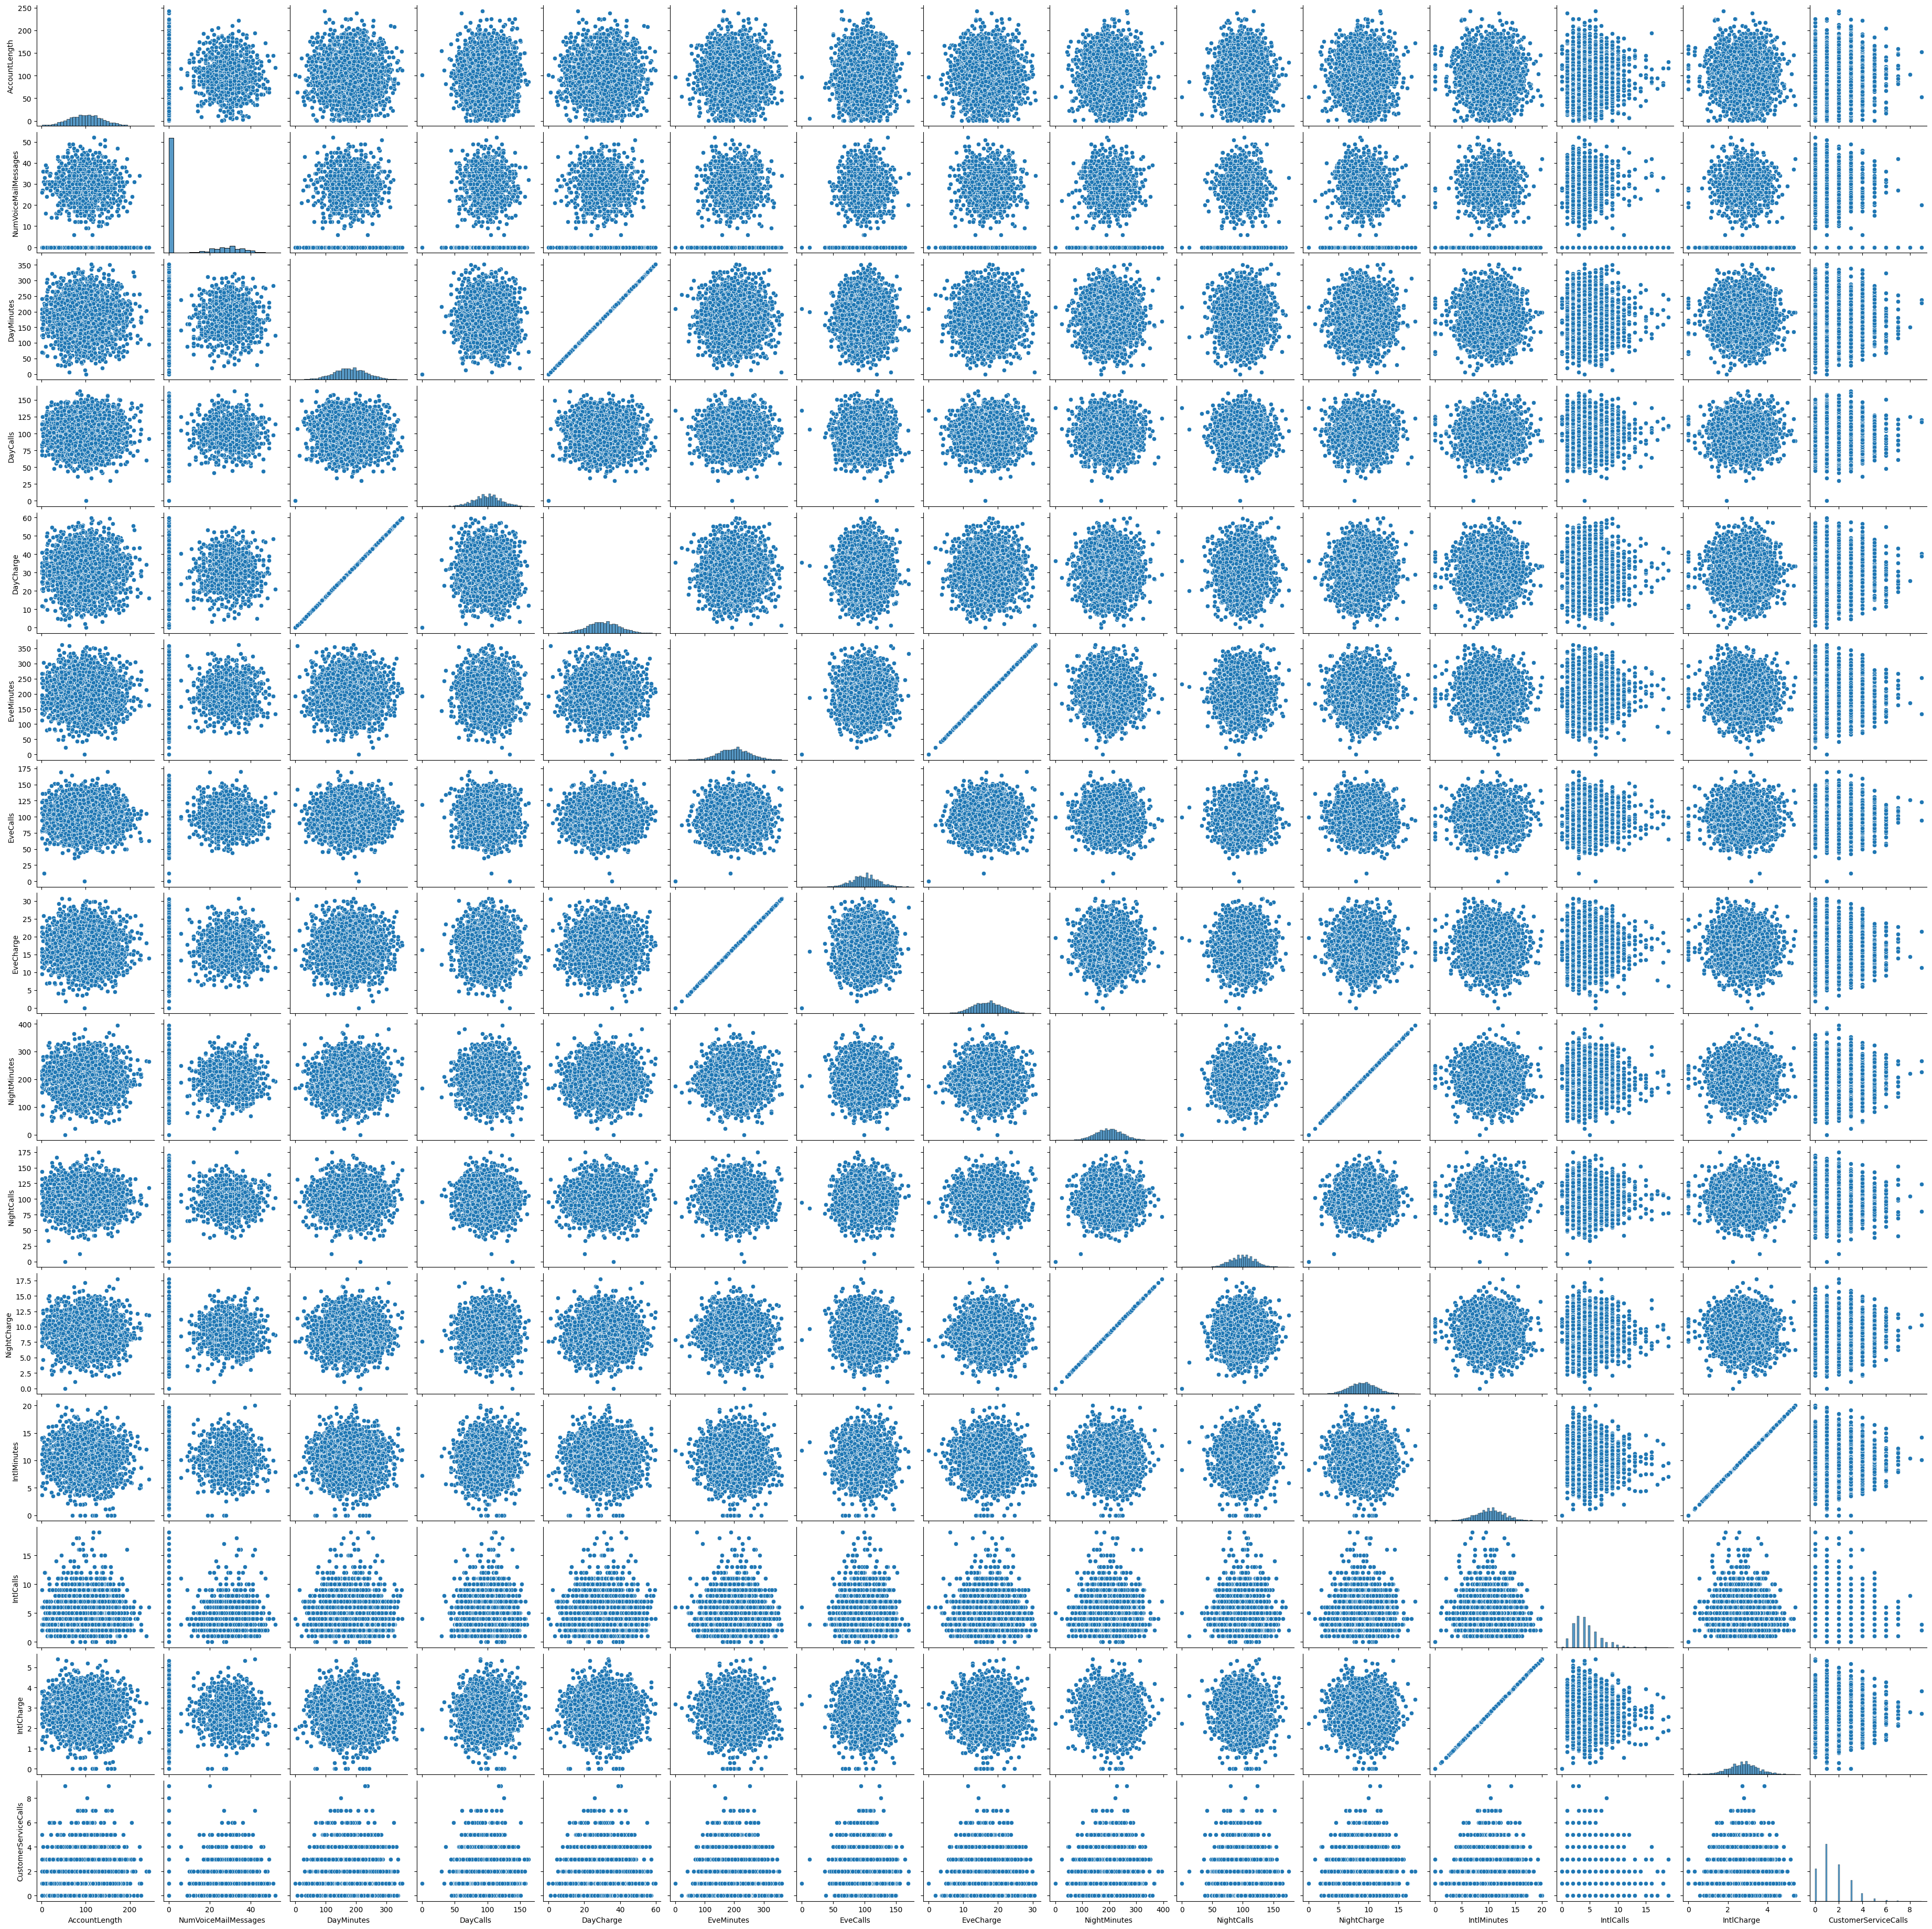

In [13]:
# Plot the pairplot for all variables
sns.pairplot(df_train.drop(columns=["CustomerId", "State", "AreaCode", "Churn", "InternationalPlan", "VoiceMailPlan"]))
plt.show()

Features look normally distributed. No strong correlations are initially observed.

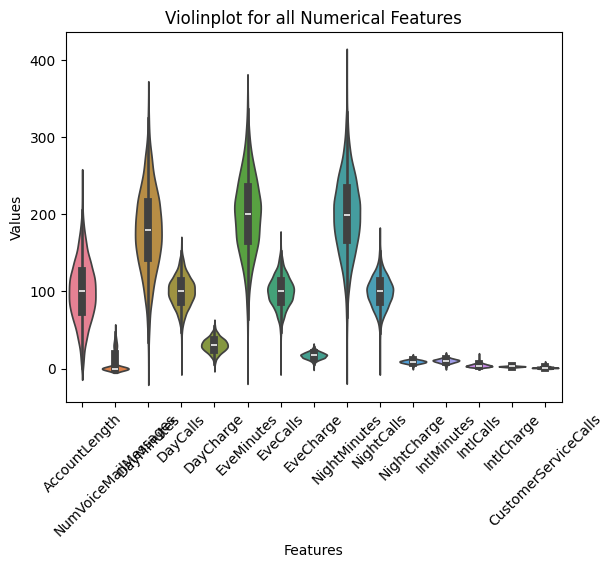

In [10]:
# Plot violinplot of all features
sns.violinplot(data=df_train.drop(columns=["CustomerId", "State", "AreaCode", "Churn"]))

plt.title("Violinplot for all Numerical Features")
plt.ylabel("Values")
plt.xlabel("Features")
plt.xticks(rotation=45)
plt.show()

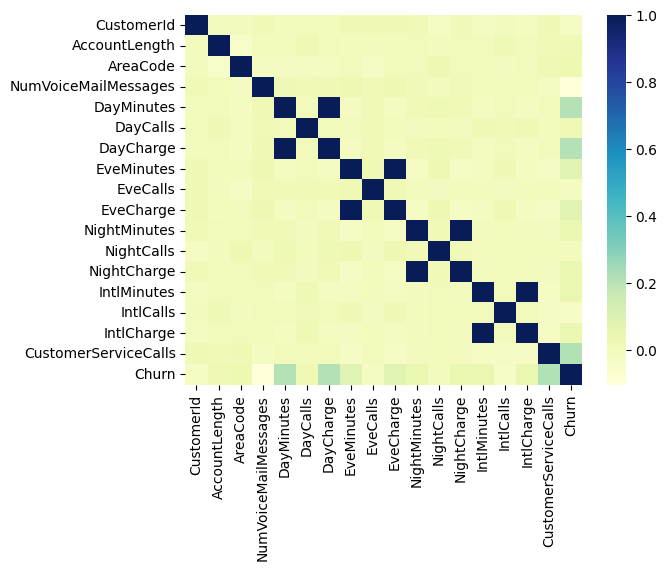

,CustomerId,AccountLength,AreaCode,NumVoiceMailMessages,DayMinutes,DayCalls,DayCharge,EveMinutes,EveCalls,EveCharge,NightMinutes,NightCalls,NightCharge,IntlMinutes,IntlCalls,IntlCharge,CustomerServiceCalls,Churn
CustomerId,1.000000,-0.009305,-0.006673,0.008303,-0.001340,0.000223,-0.001340,0.023589,0.023698,0.023588,0.013959,-0.025441,0.013968,-0.021665,-0.008894,-0.021611,0.021720,-0.026675
AccountLength,-0.009305,1.000000,-0.044753,-0.002679,0.006901,0.022971,0.006902,-0.004085,-0.006902,-0.004076,-0.000179,-0.007703,-0.000203,-0.000643,0.019426,-0.000655,0.012672,0.023283
AreaCode,-0.006673,-0.044753,1.000000,-0.018417,-0.014735,-0.016764,-0.014739,0.005296,-0.030229,0.005313,0.004184,0.027734,0.004148,0.002453,-0.013588,0.002380,0.020708,0.033873
NumVoiceMailMessages,0.008303,-0.002679,-0.018417,1.000000,0.021381,0.010980,0.021373,0.026002,0.008996,0.026012,0.009198,-0.006842,0.009183,0.005905,0.005411,0.005929,-0.016055,-0.104441
DayMinutes,-0.001340,0.006901,-0.014735,0.021381,1.000000,0.000580,1.000000,-0.020156,0.010620,-0.020167,0.010778,0.018229,0.010775,-0.017891,0.003920,-0.017815,0.003366,0.209738
DayCalls,0.000223,0.022971,-0.016764,0.010980,0.000580,1.000000,0.000581,0.006987,0.008035,0.006998,-0.011007,-0.002865,-0.011008,0.017685,0.009201,0.017687,-0.004615,0.020692
DayCharge,-0.001340,0.006902,-0.014739,0.021373,1.000000,0.000581,1.000000,-0.020150,0.010623,-0.020161,0.010782,0.018231,0.010779,-0.017896,0.003920,-0.017819,0.003360,0.209736
EveMinutes,0.023589,-0.004085,0.005296,0.026002,-0.020156,0.006987,-0.020150,1.000000,0.021194,1.000000,-0.025513,0.028105,-0.025535,-0.019369,0.021996,-0.019313,-0.029207,0.077347
EveCalls,0.023698,-0.006902,-0.030229,0.008996,0.010620,0.008035,0.010623,0.021194,1.000000,0.021212,-0.001356,-0.010984,-0.001335,-0.004951,-0.011515,-0.004952,-0.000241,-0.020547
EveCharge,0.023588,-0.004076,0.005313,0.026012,-0.020167,0.006998,-0.020161,1.000000,0.021212,1.000000,-0.025532,0.028109,-0.025554,-0.019385,0.022003,-0.019329,-0.029223,0.077339


In [11]:
# Compute correlation matrix
co_mtx = df_train.corr(numeric_only=True)

# Plot correlation heatmap
sns.heatmap(co_mtx, cmap="YlGnBu", annot=False)

# Display heatmap
plt.show()

# Show correlation matrix
co_mtx

Ver low correlations between the variables and churn. 

### Data cleaning

### Data exploration and visualisation after cleaning

### Preprocessing

### Evaluation models/ hyperparameters (cross-validation)

### Kaggle submission

### References: